# Taller 2 — Modelos de aprendizaje supervisado
**Aprendizaje Automático 1 — 2026-2** · Profesor: Daniel Rambaut · Modalidad: grupal

**Estudiantes:** Tania Fernanda Mora Cubillos · Over Haider Castrillón Valencia

Componente práctico-computacional (ejercicios 6 a 10) sobre dos conjuntos
reales incluidos en scikit-learn, por lo que el notebook se ejecuta de
principio a fin sin descargas externas:

- **Caso A** (`load_diabetes`, `scaled=False`): regresión de la progresión
  de la diabetes un año después de la medición inicial.
- **Caso B** (`load_breast_cancer`): clasificación de tejido, recodificado
  como **1 = maligno** y **0 = benigno**.

**Protocolo.** Partición fija 60/20/20 (entrenamiento, validación, prueba)
con `random_state=42`, estratificada en el caso B. Los modelos se ajustan
con entrenamiento, las decisiones se toman con validación y la prueba se
consulta una única vez, en el ejercicio 10, sobre modelos y umbrales ya
congelados.

In [1]:
import platform
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn

from sklearn.datasets import load_diabetes, load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
)

%matplotlib inline

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = False

RANDOM_STATE = 42
COLORES = {"azul": "#4C72B0", "rojo": "#C44E52", "verde": "#55A868", "gris": "#8C8C8C"}

# Rutas relativas a notebook/ (build.py ejecuta con ese directorio de trabajo).
FIG_DIR = Path("../latex/figuras")
MACROS_PATH = Path("../latex/generado/resultados.tex")

pd.Series(
    {
        "Python": platform.python_version(),
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "matplotlib": matplotlib.__version__,
        "scikit-learn": sklearn.__version__,
    },
    name="Versión",
).to_frame()

,Versión
Python,3.12.12
numpy,2.5.2
pandas,3.0.5
matplotlib,3.11.1
scikit-learn,1.9.0


### Funciones auxiliares

Se centralizan aquí las métricas y utilidades que usan varios ejercicios,
para que todas las tablas se calculen exactamente de la misma forma.

In [2]:
def rmse(y, y_pred):
    return mean_squared_error(y, y_pred) ** 0.5


def metricas_reg(y, y_pred):
    """MAE, RMSE y R² de un vector de predicciones continuas."""
    return {"MAE": mean_absolute_error(y, y_pred), "RMSE": rmse(y, y_pred), "R2": r2_score(y, y_pred)}


def predecir_umbral(proba, t):
    """Regla explícita ŷ = 1[p ≥ t] (evita los desempates internos de predict)."""
    return (np.asarray(proba) >= t).astype(int)


def metricas_clf(y, proba, t=0.5):
    """Precisión, recall, F1, ROC-AUC, FP, FN y costo L = FP + 5FN para un
    vector de probabilidades de la clase 1 (maligno) y un umbral t."""
    y_pred = predecir_umbral(proba, t)
    tn, fp, fn, tp = confusion_matrix(y, y_pred, labels=[0, 1]).ravel()
    return {
        "Umbral": t,
        "Precisión": precision_score(y, y_pred, zero_division=0),
        "Recall": recall_score(y, y_pred, zero_division=0),
        "F1": f1_score(y, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y, proba),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
        "Costo L": fp + 5 * fn,
    }


def seleccionar(tabla, orden):
    """Devuelve la fila ganadora de `tabla` aplicando criterios lexicográficos.

    `orden` es una lista de pares (columna, ascendente). Los valores reales se
    redondean a 10 decimales solo para comparar, de modo que diferencias de
    máquina no rompan un empate numérico; el ordenamiento es estable, así que
    ante un empate total gana la primera fila en el orden original de la
    cuadrícula.
    """
    claves = pd.DataFrame(index=tabla.index)
    for col, _ in orden:
        v = tabla[col]
        claves[col] = v.astype(float).round(10) if pd.api.types.is_float_dtype(v) else v
    ganador = claves.sort_values(
        [c for c, _ in orden], ascending=[a for _, a in orden], kind="mergesort"
    ).index[0]
    return tabla.loc[ganador]


def guardar_fig(fig, nombre):
    """Guarda la figura en latex/figuras/ para que el PDF use la misma imagen."""
    FIG_DIR.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIG_DIR / f"{nombre}.png", dpi=200, bbox_inches="tight")


RESULTADOS = {}


def registrar(nombre, valor, decimales=4):
    """Registra una cifra para el LaTeX como macro \\<nombre>. Los nombres
    deben ser solo letras (restricción de los comandos de LaTeX)."""
    if not re.fullmatch(r"[A-Za-z]+", nombre):
        raise ValueError(f"Nombre de macro inválido para LaTeX: {nombre!r}")
    if isinstance(valor, (int, np.integer)):
        texto = str(int(valor))
    elif isinstance(valor, (float, np.floating)):
        texto = f"{valor:.{decimales}f}"
    else:
        texto = str(valor)
    RESULTADOS[nombre] = texto
    return valor


def escribir_macros():
    """Escribe latex/generado/resultados.tex con todas las cifras registradas."""
    MACROS_PATH.parent.mkdir(parents=True, exist_ok=True)
    lineas = [
        "% Archivo generado automáticamente por el notebook (no editar a mano).",
        *(f"\\newcommand{{\\{k}}}{{{v}}}" for k, v in sorted(RESULTADOS.items())),
    ]
    MACROS_PATH.write_text("\n".join(lineas) + "\n", encoding="utf-8")
    print(f"{len(RESULTADOS)} macros escritas en {MACROS_PATH}")

### Carga y partición de los datos

Código inicial del enunciado: primero se reserva el 20 % para prueba y
luego el 25 % del 80 % restante para validación, lo que deja
aproximadamente 60/20/20.

In [3]:
def separar(X, y, clasificacion=False):
    X_dev, X_test, y_dev, y_test = train_test_split(
        X, y, test_size=0.20, random_state=RANDOM_STATE,
        stratify=y if clasificacion else None,
    )
    X_train, X_val, y_train, y_val = train_test_split(
        X_dev, y_dev, test_size=0.25, random_state=RANDOM_STATE,
        stratify=y_dev if clasificacion else None,
    )
    return X_train, X_val, X_test, y_train, y_val, y_test


diabetes = load_diabetes(as_frame=True, scaled=False)
reg = separar(diabetes.data, diabetes.target)
Xr_train, Xr_val, Xr_test, yr_train, yr_val, yr_test = reg

cancer = load_breast_cancer(as_frame=True)
y_maligno = (cancer.target == 0).astype(int)
clf = separar(cancer.data, y_maligno, clasificacion=True)
Xc_train, Xc_val, Xc_test, yc_train, yc_val, yc_test = clf

tamanos = pd.DataFrame(
    {
        "Entrenamiento": [len(Xr_train), len(Xc_train)],
        "Validación": [len(Xr_val), len(Xc_val)],
        "Prueba": [len(Xr_test), len(Xc_test)],
    },
    index=["Caso A (diabetes)", "Caso B (cáncer de mama)"],
)
print("Tabla 0.1 — Tamaño de las particiones")
tamanos

Tabla 0.1 — Tamaño de las particiones


,Entrenamiento,Validación,Prueba
Caso A (diabetes),264,89,89
Caso B (cáncer de mama),341,114,114


## Ejercicio 6 — Caso A: regresión lineal simple y modelo de referencia

### a. Exploración en entrenamiento

Toda la exploración se hace sobre `Xr_train`/`yr_train`; validación y
prueba no se miran en esta etapa.

In [4]:
print("Tabla 6.1 — Tipos, faltantes y rangos (entrenamiento)")
pd.DataFrame(
    {
        "Tipo": Xr_train.dtypes.astype(str),
        "Faltantes": Xr_train.isnull().sum(),
        "Mínimo": Xr_train.min(),
        "Máximo": Xr_train.max(),
        "Media": Xr_train.mean(),
        "Desv. est.": Xr_train.std(),
    }
)

Tabla 6.1 — Tipos, faltantes y rangos (entrenamiento)


,Tipo,Faltantes,Mínimo,Máximo,Media,Desv. est.
age,float64,0,19.0000,79.0000,48.8409,12.7693
sex,float64,0,1.0000,2.0000,1.4886,0.5008
bmi,float64,0,18.9000,41.3000,26.4894,4.3824
bp,float64,0,62.0000,126.0000,94.3068,14.0341
s1,float64,0,110.0000,301.0000,187.4659,35.2901
s2,float64,0,41.6000,242.4000,114.6087,31.3018
s3,float64,0,22.0000,98.0000,48.8466,12.3035
s4,float64,0,2.0000,9.0900,4.0897,1.2737
s5,float64,0,3.5835,6.1070,4.6534,0.5024
s6,float64,0,58.0000,124.0000,92.3523,11.4221


In [5]:
print(f"Faltantes en la variable objetivo (entrenamiento): {yr_train.isnull().sum()}")
print("Tabla 6.2 — Resumen de la variable objetivo (entrenamiento)")
yr_train.describe().to_frame("target")

Faltantes en la variable objetivo (entrenamiento): 0
Tabla 6.2 — Resumen de la variable objetivo (entrenamiento)


,target
count,264.0000
mean,149.8106
std,78.9959
min,25.0000
25%,83.0000
50%,136.0000
75%,206.5000
max,346.0000


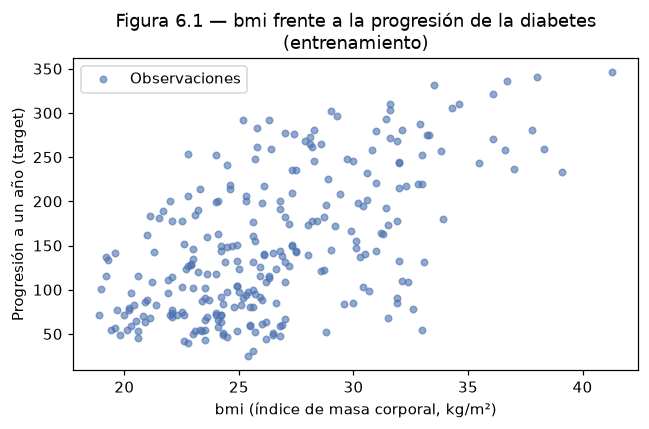

Correlación de Pearson bmi–target (entrenamiento): 0.5954


In [6]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(Xr_train["bmi"], yr_train, s=18, alpha=0.6, color=COLORES["azul"], label="Observaciones")
ax.set_title("Figura 6.1 — bmi frente a la progresión de la diabetes\n(entrenamiento)")
ax.set_xlabel("bmi (índice de masa corporal, kg/m²)")
ax.set_ylabel("Progresión a un año (target)")
ax.legend()
plt.tight_layout()
guardar_fig(fig, "ex6_bmi_target")
plt.show()

print(f"Correlación de Pearson bmi–target (entrenamiento): "
      f"{registrar('CorrBmiTarget', Xr_train['bmi'].corr(yr_train)):.4f}")

TODO: análisis 6a

### b. Regresión simple con NumPy vs. `LinearRegression`

Se implementan las expresiones del ejercicio 1,
$\hat\beta_1 = \sum_i (x_i-\bar x)(y_i-\bar y) / \sum_i (x_i-\bar x)^2$ y
$\hat\beta_0 = \bar y - \hat\beta_1 \bar x$, usando solo `bmi`.

In [7]:
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor

x_tr = Xr_train["bmi"].to_numpy()
y_tr = yr_train.to_numpy()
x_bar, y_bar = x_tr.mean(), y_tr.mean()
beta1_np = np.sum((x_tr - x_bar) * (y_tr - y_bar)) / np.sum((x_tr - x_bar) ** 2)
beta0_np = y_bar - beta1_np * x_bar

lr_simple = LinearRegression().fit(Xr_train[["bmi"]], yr_train)

pred_val_np = beta0_np + beta1_np * Xr_val["bmi"].to_numpy()
pred_val_sk = lr_simple.predict(Xr_val[["bmi"]])
dif_max = np.max(np.abs(pred_val_np - pred_val_sk))

print("Tabla 6.3 — Coeficientes de la regresión simple (entrenamiento)")
display(
    pd.DataFrame(
        {"NumPy": [beta0_np, beta1_np], "LinearRegression": [lr_simple.intercept_, lr_simple.coef_[0]]},
        index=["β0 (intercepto)", "β1 (pendiente bmi)"],
    )
)
print(f"Diferencia absoluta máxima entre predicciones de validación: {dif_max:.3e}")
print(f"np.allclose(NumPy, sklearn): {np.allclose(pred_val_np, pred_val_sk)}")
if dif_max == 0:
    registrar("SimpleDifMax", "0")
else:
    exp = int(np.floor(np.log10(dif_max)))
    registrar("SimpleDifMax", f"{dif_max / 10**exp:.1f}\\times 10^{{{exp}}}")

Tabla 6.3 — Coeficientes de la regresión simple (entrenamiento)


,NumPy,LinearRegression
β0 (intercepto),-134.5023,-134.5023
β1 (pendiente bmi),10.7331,10.7331


Diferencia absoluta máxima entre predicciones de validación: 5.684e-14
np.allclose(NumPy, sklearn): True


TODO: análisis 6b

### c. Comparación con `DummyRegressor`

In [8]:
dummy_reg = DummyRegressor(strategy="mean").fit(Xr_train, yr_train)

filas = []
for nombre, modelo, cols in [
    ("Constante (media)", dummy_reg, list(Xr_train.columns)),
    ("Regresión simple (bmi)", lr_simple, ["bmi"]),
]:
    for particion, X_, y_ in [("Entrenamiento", Xr_train, yr_train), ("Validación", Xr_val, yr_val)]:
        filas.append({"Modelo": nombre, "Partición": particion, **metricas_reg(y_, modelo.predict(X_[cols]))})
tabla_6c = pd.DataFrame(filas).set_index(["Modelo", "Partición"])
print("Tabla 6.4 — Constante vs. regresión simple (entrenamiento y validación)")
tabla_6c

Tabla 6.4 — Constante vs. regresión simple (entrenamiento y validación)


MAE    RMSE      R2
Modelo                 Partición                            
Constante (media)      Entrenamiento 66.6773 78.8462  0.0000
                       Validación    64.1288 75.6392 -0.0443
Regresión simple (bmi) Entrenamiento 51.5459 63.3458  0.3545
                       Validación    50.3475 58.5671  0.3739

In [9]:
for clave, nombre in [("Dummy", "Constante (media)"), ("Simple", "Regresión simple (bmi)")]:
    for sufijo, particion in [("Tr", "Entrenamiento"), ("Val", "Validación")]:
        for met in ["MAE", "RMSE", "R2"]:
            registrar(f"Reg{clave}{met.replace('2', 'dos')}{sufijo}", tabla_6c.loc[(nombre, particion), met])

TODO: análisis 6c

### d. Residuos de validación

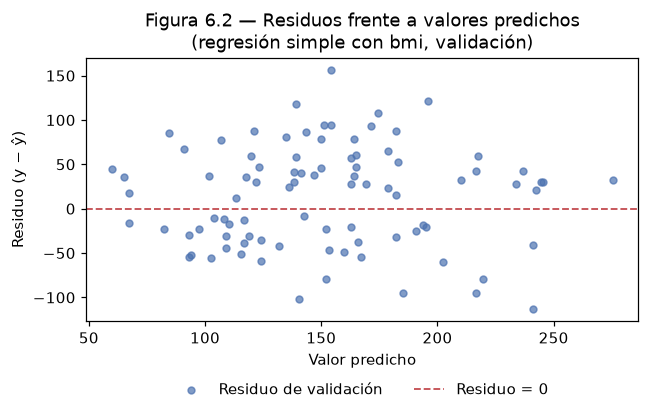

Desv. est. de residuos, mitad de predicciones bajas: 50.7598
Desv. est. de residuos, mitad de predicciones altas: 62.3648
Residuo mínimo: -113.1556 · residuo máximo: 156.7823


In [10]:
res_val = yr_val.to_numpy() - pred_val_sk
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(pred_val_sk, res_val, s=20, alpha=0.7, color=COLORES["azul"], label="Residuo de validación")
ax.axhline(0, color=COLORES["rojo"], linestyle="--", linewidth=1.2, label="Residuo = 0")
ax.set_title("Figura 6.2 — Residuos frente a valores predichos\n(regresión simple con bmi, validación)")
ax.set_xlabel("Valor predicho")
ax.set_ylabel("Residuo (y − ŷ)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2, frameon=False)
plt.tight_layout()
guardar_fig(fig, "ex6_residuos")
plt.show()

orden_pred = np.argsort(pred_val_sk)
mitad = len(orden_pred) // 2
print(f"Desv. est. de residuos, mitad de predicciones bajas: {res_val[orden_pred[:mitad]].std():.4f}")
print(f"Desv. est. de residuos, mitad de predicciones altas: {res_val[orden_pred[mitad:]].std():.4f}")
print(f"Residuo mínimo: {res_val.min():.4f} · residuo máximo: {res_val.max():.4f}")

TODO: análisis 6d

### e. Interpretación de coeficientes

In [11]:
print(f"Intercepto: {registrar('SimpleBetaCero', lr_simple.intercept_):.4f}")
print(f"Pendiente (bmi): {registrar('SimpleBetaUno', lr_simple.coef_[0]):.4f}")

Intercepto: -134.5023
Pendiente (bmi): 10.7331


TODO: análisis 6e

## Ejercicio 7 — Caso A: regresión múltiple y árbol de regresión

### a. Regresión múltiple con `Pipeline`

El `StandardScaler` vive dentro del `Pipeline`, de modo que sus medias y
desviaciones se aprenden solo con entrenamiento y se reutilizan tal cual
al predecir validación.

In [12]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor

pipe_multi = Pipeline(
    [("escalador", StandardScaler()), ("regresion", LinearRegression())]
).fit(Xr_train, yr_train)

filas = []
for nombre, modelo, cols in [
    ("Constante (media)", dummy_reg, list(Xr_train.columns)),
    ("Regresión simple (bmi)", lr_simple, ["bmi"]),
    ("Regresión múltiple (10 predictores)", pipe_multi, list(Xr_train.columns)),
]:
    for particion, X_, y_ in [("Entrenamiento", Xr_train, yr_train), ("Validación", Xr_val, yr_val)]:
        filas.append({"Modelo": nombre, "Partición": particion, **metricas_reg(y_, modelo.predict(X_[cols]))})
tabla_7a = pd.DataFrame(filas).set_index(["Modelo", "Partición"])
print("Tabla 7.1 — Constante, regresión simple y múltiple (entrenamiento y validación)")
tabla_7a

Tabla 7.1 — Constante, regresión simple y múltiple (entrenamiento y validación)


MAE    RMSE      R2
Modelo                              Partición                            
Constante (media)                   Entrenamiento 66.6773 78.8462  0.0000
                                    Validación    64.1288 75.6392 -0.0443
Regresión simple (bmi)              Entrenamiento 51.5459 63.3458  0.3545
                                    Validación    50.3475 58.5671  0.3739
Regresión múltiple (10 predictores) Entrenamiento 43.7935 54.6104  0.5203
                                    Validación    42.9389 51.1937  0.5216

In [13]:
for sufijo, particion in [("Tr", "Entrenamiento"), ("Val", "Validación")]:
    for met in ["MAE", "RMSE", "R2"]:
        registrar(f"RegMulti{met.replace('2', 'dos')}{sufijo}",
                  tabla_7a.loc[("Regresión múltiple (10 predictores)", particion), met])

TODO: análisis 7a

### b. Coeficientes estandarizados y correlaciones

Como los predictores entran estandarizados, cada coeficiente es el cambio
esperado en la variable objetivo ante un aumento de una desviación
estándar de entrenamiento en ese predictor, manteniendo fijos los demás.

In [14]:
escalador = pipe_multi.named_steps["escalador"]
coefs_multi = pd.DataFrame(
    {
        "Coeficiente": pipe_multi.named_steps["regresion"].coef_,
        "Desv. est. entrenamiento": escalador.scale_,
    },
    index=Xr_train.columns,
)
coefs_multi["|Coeficiente|"] = coefs_multi["Coeficiente"].abs()
coefs_multi = coefs_multi.sort_values("|Coeficiente|", ascending=False)
print(f"Intercepto (media de y en entrenamiento): {pipe_multi.named_steps['regresion'].intercept_:.4f}")
print("Tabla 7.2 — Coeficientes estandarizados de la regresión múltiple, por magnitud absoluta")
coefs_multi

Intercepto (media de y en entrenamiento): 149.8106
Tabla 7.2 — Coeficientes estandarizados de la regresión múltiple, por magnitud absoluta


,Coeficiente,Desv. est. entrenamiento,|Coeficiente|
s1,-51.1014,35.2232,51.1014
s5,37.2716,0.5015,37.2716
s2,27.4808,31.2424,27.4808
bmi,25.0766,4.3741,25.0766
bp,15.1673,14.0075,15.1673
s4,15.0321,1.2713,15.0321
sex,-11.3593,0.4999,11.3593
s3,10.8403,12.2802,10.8403
s6,3.8171,11.4005,3.8171
age,1.1318,12.7451,1.1318


In [15]:
for var in ["bmi", "s5", "s1", "s2"]:
    nombre = var.capitalize().replace("1", "uno").replace("2", "dos").replace("5", "cinco")
    registrar(f"CoefMulti{nombre}", coefs_multi.loc[var, "Coeficiente"], 2)
    registrar(f"DesvMulti{nombre}", coefs_multi.loc[var, "Desv. est. entrenamiento"], 2)

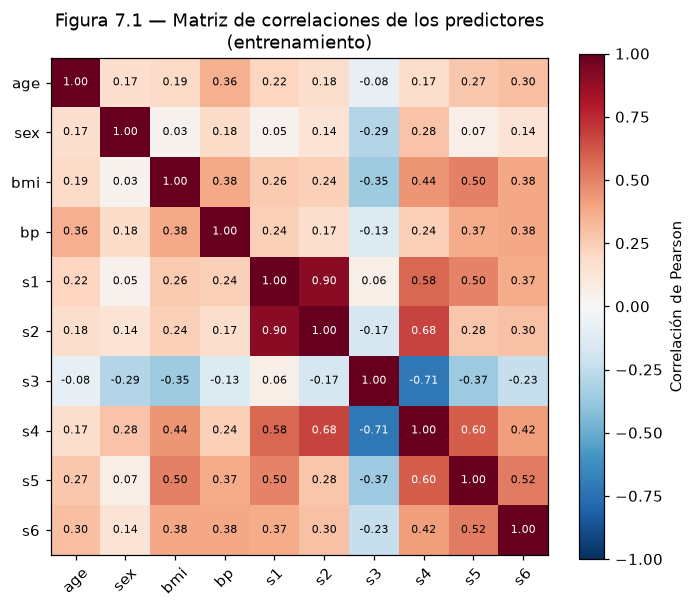

Tabla 7.3 — Pares de predictores más correlacionados (entrenamiento)


,,Correlación,|Correlación|
s1,s2,0.9023,0.9023
s3,s4,-0.7143,0.7143
s2,s4,0.6765,0.6765
s4,s5,0.6038,0.6038
s1,s4,0.5766,0.5766


In [16]:
corr_tr = Xr_train.corr()
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(corr_tr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_tr)), corr_tr.columns, rotation=45)
ax.set_yticks(range(len(corr_tr)), corr_tr.columns)
for i in range(len(corr_tr)):
    for j in range(len(corr_tr)):
        v = corr_tr.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(v) > 0.6 else "black")
fig.colorbar(im, ax=ax, label="Correlación de Pearson")
ax.set_title("Figura 7.1 — Matriz de correlaciones de los predictores\n(entrenamiento)")
plt.tight_layout()
guardar_fig(fig, "ex7_correlaciones")
plt.show()

pares = (
    corr_tr.where(np.triu(np.ones(corr_tr.shape, dtype=bool), k=1))
    .stack().rename("Correlación").to_frame()
)
pares["|Correlación|"] = pares["Correlación"].abs()
print("Tabla 7.3 — Pares de predictores más correlacionados (entrenamiento)")
pares.sort_values("|Correlación|", ascending=False).head(5)

In [17]:
registrar("CorrSunoSdos", corr_tr.loc["s1", "s2"])
_ = registrar("CorrStresScuatro", corr_tr.loc["s3", "s4"])

TODO: análisis 7b

### c. Cuadrícula de `DecisionTreeRegressor`

Se ajustan los nueve árboles sobre los predictores originales (sin
escalar). Regla de selección: menor RMSE de validación; en empate, menor
`max_depth` y después mayor `min_samples_leaf`.

In [18]:
filas, arboles_reg = [], {}
for max_depth in [2, 4, 6]:
    for min_leaf in [5, 15, 30]:
        arbol = DecisionTreeRegressor(
            criterion="squared_error", max_depth=max_depth,
            min_samples_leaf=min_leaf, random_state=RANDOM_STATE,
        ).fit(Xr_train, yr_train)
        arboles_reg[(max_depth, min_leaf)] = arbol
        filas.append({
            "max_depth": max_depth, "min_samples_leaf": min_leaf,
            "RMSE entrenamiento": rmse(yr_train, arbol.predict(Xr_train)),
            "RMSE validación": rmse(yr_val, arbol.predict(Xr_val)),
            "Profundidad real": arbol.get_depth(), "Hojas": arbol.get_n_leaves(),
        })
tabla_7c = pd.DataFrame(filas)
tabla_7c["Brecha (val − ent)"] = tabla_7c["RMSE validación"] - tabla_7c["RMSE entrenamiento"]
print("Tabla 7.4 — Cuadrícula de árboles de regresión (RMSE en entrenamiento y validación)")
tabla_7c

Tabla 7.4 — Cuadrícula de árboles de regresión (RMSE en entrenamiento y validación)


,max_depth,min_samples_leaf,RMSE entrenamiento,RMSE validación,Profundidad real,Hojas,Brecha (val − ent)
0,2,5,57.6273,58.7814,2,4,1.1541
1,2,15,57.6273,58.7814,2,4,1.1541
2,2,30,59.0808,57.3406,2,4,-1.7402
3,4,5,49.0068,61.0539,4,15,12.0471
4,4,15,52.7463,58.1889,4,10,5.4425
5,4,30,58.0732,56.7789,4,6,-1.2943
6,6,5,38.5411,63.2140,6,31,24.6729
7,6,15,52.1941,57.9781,6,12,5.7840
8,6,30,58.0732,56.7789,4,6,-1.2943


In [19]:
sel_arbol_reg = seleccionar(
    tabla_7c, [("RMSE validación", True), ("max_depth", True), ("min_samples_leaf", False)]
)
arbol_reg = arboles_reg[(int(sel_arbol_reg["max_depth"]), int(sel_arbol_reg["min_samples_leaf"]))]
n_empatados = int(np.isclose(tabla_7c["RMSE validación"], sel_arbol_reg["RMSE validación"], rtol=0, atol=1e-10).sum())
print(f"Árbol seleccionado: max_depth={int(sel_arbol_reg['max_depth'])}, "
      f"min_samples_leaf={int(sel_arbol_reg['min_samples_leaf'])} "
      f"(RMSE validación = {sel_arbol_reg['RMSE validación']:.4f}; "
      f"árboles con ese mismo RMSE: {n_empatados})")

registrar("ArbolRegMaxDepth", int(sel_arbol_reg["max_depth"]))
registrar("ArbolRegMinLeaf", int(sel_arbol_reg["min_samples_leaf"]))
registrar("ArbolRegProf", int(sel_arbol_reg["Profundidad real"]))
registrar("ArbolRegHojas", int(sel_arbol_reg["Hojas"]))
registrar("ArbolRegRMSETr", sel_arbol_reg["RMSE entrenamiento"])
registrar("ArbolRegRMSEVal", sel_arbol_reg["RMSE validación"])
_ = registrar("ArbolRegEmpatados", n_empatados)

Árbol seleccionado: max_depth=4, min_samples_leaf=30 (RMSE validación = 56.7789; árboles con ese mismo RMSE: 2)


TODO: análisis 7c

### d. Candidato final de regresión

Se elige por menor RMSE de validación; en empate numérico se prefiere el
modelo simple, luego el múltiple y después el árbol (columna `Orden`).

In [20]:
filas = []
for orden, (nombre, modelo, cols) in enumerate([
    ("Regresión simple (bmi)", lr_simple, ["bmi"]),
    ("Regresión múltiple (10 predictores)", pipe_multi, list(Xr_train.columns)),
    (f"Árbol (max_depth={arbol_reg.max_depth}, min_samples_leaf={arbol_reg.min_samples_leaf})",
     arbol_reg, list(Xr_train.columns)),
]):
    filas.append({
        "Modelo": nombre, "Orden": orden,
        **{f"{k} ent.": v for k, v in metricas_reg(yr_train, modelo.predict(Xr_train[cols])).items()},
        **{f"{k} val.": v for k, v in metricas_reg(yr_val, modelo.predict(Xr_val[cols])).items()},
    })
tabla_7d = pd.DataFrame(filas)
tabla_7d.loc[len(tabla_7d)] = {
    "Modelo": "Constante (media) — referencia", "Orden": np.nan,
    **{f"{k} ent.": v for k, v in metricas_reg(yr_train, dummy_reg.predict(Xr_train)).items()},
    **{f"{k} val.": v for k, v in metricas_reg(yr_val, dummy_reg.predict(Xr_val)).items()},
}
print("Tabla 7.5 — Comparación de candidatos de regresión (entrenamiento y validación)")
display(tabla_7d.set_index("Modelo").drop(columns="Orden"))

candidato_reg = seleccionar(tabla_7d.dropna(subset=["Orden"]), [("RMSE val.", True), ("Orden", True)])
modelos_reg = {
    "Regresión simple (bmi)": (lr_simple, ["bmi"]),
    "Regresión múltiple (10 predictores)": (pipe_multi, list(Xr_train.columns)),
    tabla_7d.loc[2, "Modelo"]: (arbol_reg, list(Xr_train.columns)),
}
modelo_reg_final, cols_reg_final = modelos_reg[candidato_reg["Modelo"]]
print(f"Candidato final de regresión (congelado): {candidato_reg['Modelo']} "
      f"(RMSE validación = {candidato_reg['RMSE val.']:.4f})")
_ = registrar("CandidatoRegRMSEVal", candidato_reg["RMSE val."])

Tabla 7.5 — Comparación de candidatos de regresión (entrenamiento y validación)


,MAE ent.,RMSE ent.,R2 ent.,MAE val.,RMSE val.,R2 val.
Modelo,,,,,,
Regresión simple (bmi),51.5459,63.3458,0.3545,50.3475,58.5671,0.3739
Regresión múltiple (10 predictores),43.7935,54.6104,0.5203,42.9389,51.1937,0.5216
"Árbol (max_depth=4, min_samples_leaf=30)",46.5549,58.0732,0.4575,45.3006,56.7789,0.4116
Constante (media) — referencia,66.6773,78.8462,0.0000,64.1288,75.6392,-0.0443


Candidato final de regresión (congelado): Regresión múltiple (10 predictores) (RMSE validación = 51.1937)


TODO: análisis 7d

### e. No linealidad y brecha entrenamiento–validación

In [21]:
brechas = pd.DataFrame({
    "RMSE ent.": tabla_7d.set_index("Modelo")["RMSE ent."],
    "RMSE val.": tabla_7d.set_index("Modelo")["RMSE val."],
})
brechas["Brecha (val − ent)"] = brechas["RMSE val."] - brechas["RMSE ent."]
print("Tabla 7.6 — Brecha de RMSE entre validación y entrenamiento")
brechas

Tabla 7.6 — Brecha de RMSE entre validación y entrenamiento


,RMSE ent.,RMSE val.,Brecha (val − ent)
Modelo,,,
Regresión simple (bmi),63.3458,58.5671,-4.7787
Regresión múltiple (10 predictores),54.6104,51.1937,-3.4166
"Árbol (max_depth=4, min_samples_leaf=30)",58.0732,56.7789,-1.2943
Constante (media) — referencia,78.8462,75.6392,-3.2070


TODO: análisis 7e

## Ejercicio 8 — Caso B: regresión logística y elección del umbral

### a. Particiones, recodificación y referencia

In [22]:
import warnings

from sklearn.dummy import DummyClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression

print("Tabla 8.1 — Recodificación de la clase positiva (conjunto completo)")
display(pd.crosstab(
    pd.Series(cancer.target_names[cancer.target], name="Etiqueta original"),
    pd.Series(y_maligno.to_numpy(), name="y recodificada (1 = maligno)"),
))

prop = pd.DataFrame({
    "n": [len(yc_train), len(yc_val)],
    "Malignos": [int(yc_train.sum()), int(yc_val.sum())],
    "Proporción de malignos": [yc_train.mean(), yc_val.mean()],
}, index=["Entrenamiento", "Validación"])
print("Tabla 8.2 — Proporción de la clase positiva por partición")
display(prop)
registrar("PropMalTr", yc_train.mean())
_ = registrar("PropMalVal", yc_val.mean())

Tabla 8.1 — Recodificación de la clase positiva (conjunto completo)


y recodificada (1 = maligno),0,1
Etiqueta original,,
benign,357,0
malignant,0,212


Tabla 8.2 — Proporción de la clase positiva por partición


,n,Malignos,Proporción de malignos
Entrenamiento,341,127,0.3724
Validación,114,43,0.3772


In [23]:
dummy_clf = DummyClassifier(strategy="prior").fit(Xc_train, yc_train)
filas = []
for particion, X_, y_ in [("Entrenamiento", Xc_train, yc_train), ("Validación", Xc_val, yc_val)]:
    filas.append({"Partición": particion, **metricas_clf(y_, dummy_clf.predict_proba(X_)[:, 1], 0.5)})
tabla_8a = pd.DataFrame(filas).set_index("Partición")
print(f"Probabilidad constante de maligno que asigna la referencia: {dummy_clf.predict_proba(Xc_val[:1])[0, 1]:.4f}")
print("Tabla 8.3 — Clasificador de referencia (prior), umbral 0.5")
tabla_8a

Probabilidad constante de maligno que asigna la referencia: 0.3724
Tabla 8.3 — Clasificador de referencia (prior), umbral 0.5


,Umbral,Precisión,Recall,F1,ROC-AUC,TN,FP,FN,TP,Costo L
Partición,,,,,,,,,,
Entrenamiento,0.5000,0.0000,0.0000,0.0000,0.5000,214,0,127,0,635
Validación,0.5000,0.0000,0.0000,0.0000,0.5000,71,0,43,0,215


TODO: análisis 8a

### b. Selección de $C$

Regla: mayor ROC-AUC de validación; en empate, menor $C$. La convergencia
se verifica de dos formas, capturando cualquier `ConvergenceWarning` y
comprobando que el número de iteraciones usadas sea menor que `max_iter`.

In [24]:
filas, logits = [], {}
for C in [0.01, 0.1, 1, 10]:
    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter("always", ConvergenceWarning)
        logit = Pipeline([
            ("escalador", StandardScaler()),
            ("logistica", LogisticRegression(C=C, solver="lbfgs", max_iter=5000)),
        ]).fit(Xc_train, yc_train)
    logits[C] = logit
    p_tr = logit.predict_proba(Xc_train)[:, 1]
    p_val = logit.predict_proba(Xc_val)[:, 1]
    n_iter = int(logit.named_steps["logistica"].n_iter_[0])
    filas.append({
        "C": C,
        "ROC-AUC ent.": roc_auc_score(yc_train, p_tr),
        "ROC-AUC val.": roc_auc_score(yc_val, p_val),
        "F1 ent. (t=0.5)": f1_score(yc_train, predecir_umbral(p_tr, 0.5), zero_division=0),
        "F1 val. (t=0.5)": f1_score(yc_val, predecir_umbral(p_val, 0.5), zero_division=0),
        "Iteraciones": n_iter,
        "Convergió": n_iter < 5000 and not any(issubclass(a.category, ConvergenceWarning) for a in avisos),
    })
tabla_8b = pd.DataFrame(filas)
print("Tabla 8.4 — Regresión logística según C (entrenamiento y validación)")
tabla_8b

Tabla 8.4 — Regresión logística según C (entrenamiento y validación)


,C,ROC-AUC ent.,ROC-AUC val.,F1 ent. (t=0.5),F1 val. (t=0.5),Iteraciones,Convergió
0,0.0100,0.9927,0.9905,0.9283,0.9512,10,True
1,0.1000,0.9955,0.9951,0.9721,0.9762,10,True
2,1.0000,0.9979,0.9957,0.9840,0.9655,18,True
3,10.0000,0.9997,0.9957,0.9960,0.9545,33,True


In [25]:
sel_C = seleccionar(tabla_8b, [("ROC-AUC val.", False), ("C", True)])
C_sel = float(sel_C["C"])
logit_sel = logits[C_sel]
assert tabla_8b["Convergió"].all(), "Algún ajuste no convergió"
empate_C = np.isclose(tabla_8b["ROC-AUC val."], sel_C["ROC-AUC val."], rtol=0, atol=1e-10)
print("ROC-AUC de validación a precisión completa:",
      {f"C={c:g}": f"{v:.10f}" for c, v in zip(tabla_8b["C"], tabla_8b["ROC-AUC val."])})
print(f"Valores de C empatados en el máximo: {tabla_8b.loc[empate_C, 'C'].tolist()}")
print(f"C seleccionado: {C_sel:g} (ROC-AUC validación = {sel_C['ROC-AUC val.']:.4f})")
registrar("LogitEmpatesC", int(empate_C.sum()))
registrar("LogitC", f"{C_sel:g}")
registrar("LogitAUCVal", sel_C["ROC-AUC val."])
registrar("LogitAUCTr", sel_C["ROC-AUC ent."])
registrar("LogitFUnoVal", sel_C["F1 val. (t=0.5)"])
_ = registrar("LogitIterMax", int(tabla_8b["Iteraciones"].max()))

ROC-AUC de validación a precisión completa: {'C=0.01': '0.9905011464', 'C=0.1': '0.9950867999', 'C=1': '0.9957418932', 'C=10': '0.9957418932'}
Valores de C empatados en el máximo: [1.0, 10.0]
C seleccionado: 1 (ROC-AUC validación = 0.9957)


TODO: análisis 8b

### c. Umbral por costo $L = FP + 5FN$

El modelo queda fijo; solo se cambia la regla $\hat y = \mathbb{1}[p \ge t]$
sobre validación. Regla: menor $L$; en empate, mayor recall y después menor
umbral.

In [26]:
UMBRALES = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]


def tabla_umbrales(y, proba):
    cols = ["Umbral", "Precisión", "Recall", "F1", "FP", "FN", "Costo L"]
    return pd.DataFrame([metricas_clf(y, proba, t) for t in UMBRALES])[cols]


p_val_logit = logit_sel.predict_proba(Xc_val)[:, 1]
tabla_8c = tabla_umbrales(yc_val, p_val_logit)
print(f"Tabla 8.5 — Umbrales para la regresión logística con C = {C_sel:g} (validación)")
tabla_8c

Tabla 8.5 — Umbrales para la regresión logística con C = 1 (validación)


,Umbral,Precisión,Recall,F1,FP,FN,Costo L
0,0.2000,0.8400,0.9767,0.9032,8,1,13
1,0.3000,0.9130,0.9767,0.9438,4,1,9
2,0.4000,0.9545,0.9767,0.9655,2,1,7
3,0.5000,0.9545,0.9767,0.9655,2,1,7
4,0.6000,0.9545,0.9767,0.9655,2,1,7
5,0.7000,1.0000,0.9767,0.9882,0,1,5
6,0.8000,1.0000,0.9767,0.9882,0,1,5


In [27]:
sel_t_logit = seleccionar(tabla_8c, [("Costo L", True), ("Recall", False), ("Umbral", True)])
t_logit = float(sel_t_logit["Umbral"])
fila_05 = tabla_8c.set_index("Umbral").loc[0.5]
print(f"Umbral seleccionado (congelado): t = {t_logit} con L = {int(sel_t_logit['Costo L'])} "
      f"(FP = {int(sel_t_logit['FP'])}, FN = {int(sel_t_logit['FN'])})")
print(f"Con t = 0.5: L = {int(fila_05['Costo L'])} (FP = {int(fila_05['FP'])}, FN = {int(fila_05['FN'])})")
print("Umbrales con el costo mínimo:", tabla_8c.loc[tabla_8c["Costo L"] == sel_t_logit["Costo L"], "Umbral"].tolist())

registrar("LogitT", f"{t_logit:.1f}")
for nombre, fila in [("Sel", sel_t_logit), ("Medio", fila_05)]:
    registrar(f"LogitCosto{nombre}", int(fila["Costo L"]))
    registrar(f"LogitFP{nombre}", int(fila["FP"]))
    registrar(f"LogitFN{nombre}", int(fila["FN"]))
    registrar(f"LogitRecall{nombre}", fila["Recall"])
    _ = registrar(f"LogitPrec{nombre}", fila["Precisión"])

Umbral seleccionado (congelado): t = 0.7 con L = 5 (FP = 0, FN = 1)
Con t = 0.5: L = 7 (FP = 2, FN = 1)
Umbrales con el costo mínimo: [0.7, 0.8]


TODO: análisis 8c

### d. Precisión y recall frente al umbral

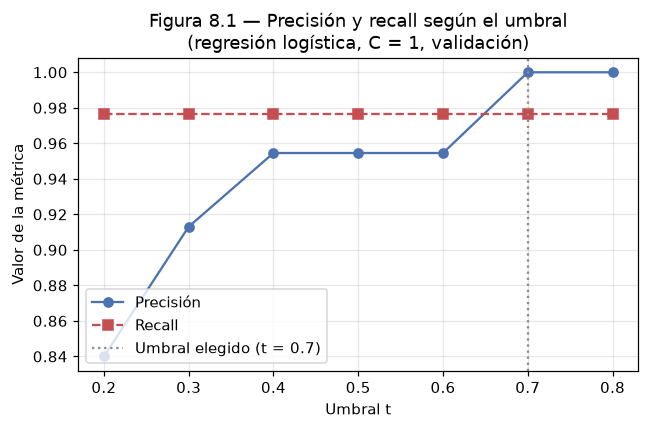

ROC-AUC de validación (no depende de t): 0.9957


In [28]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(tabla_8c["Umbral"], tabla_8c["Precisión"], marker="o", color=COLORES["azul"], label="Precisión")
ax.plot(tabla_8c["Umbral"], tabla_8c["Recall"], marker="s", linestyle="--", color=COLORES["rojo"], label="Recall")
ax.axvline(t_logit, color=COLORES["gris"], linestyle=":", label=f"Umbral elegido (t = {t_logit})")
ax.set_title(f"Figura 8.1 — Precisión y recall según el umbral\n(regresión logística, C = {C_sel:g}, validación)")
ax.set_xlabel("Umbral t")
ax.set_ylabel("Valor de la métrica")
ax.legend(loc="lower left")
ax.grid(alpha=0.3)
plt.tight_layout()
guardar_fig(fig, "ex8_precision_recall")
plt.show()

print(f"ROC-AUC de validación (no depende de t): {roc_auc_score(yc_val, p_val_logit):.4f}")

TODO: análisis 8d

### e. Coeficientes estandarizados y odds

In [29]:
coefs_logit = pd.DataFrame(
    {"Coeficiente": logit_sel.named_steps["logistica"].coef_[0]}, index=Xc_train.columns
)
coefs_logit["exp(β)"] = np.exp(coefs_logit["Coeficiente"])
coefs_logit["|Coeficiente|"] = coefs_logit["Coeficiente"].abs()
coefs_logit = coefs_logit.sort_values("|Coeficiente|", ascending=False)
print(f"Tabla 8.6 — Coeficientes estandarizados de la regresión logística (C = {C_sel:g}), por magnitud absoluta")
coefs_logit

Tabla 8.6 — Coeficientes estandarizados de la regresión logística (C = 1), por magnitud absoluta


,Coeficiente,exp(β),|Coeficiente|
worst texture,1.3553,3.8780,1.3553
mean concave points,1.1043,3.0171,1.1043
radius error,1.0259,2.7897,1.0259
worst symmetry,0.9519,2.5905,0.9519
worst radius,0.8134,2.2556,0.8134
worst area,0.7948,2.2140,0.7948
area error,0.7822,2.1864,0.7822
worst concavity,0.7689,2.1575,0.7689
mean concavity,0.7621,2.1428,0.7621
compactness error,-0.7591,0.4681,0.7591


TODO: análisis 8e

## Ejercicio 9 — Caso B: árbol de clasificación e interpretación

### a. Cuadrícula de `DecisionTreeClassifier`

Se usan los mismos predictores originales y particiones, sin estandarizar
(los cortes de un árbol son invariantes a transformaciones monótonas de
cada variable). La cuadrícula se recorre en el orden del enunciado,
`max_depth` por fuera y `min_samples_leaf` por dentro, porque ese orden es
el último criterio de desempate.

In [30]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

filas, arboles_clf = [], []
for max_depth in [2, 3, 5, None]:
    for min_leaf in [1, 5, 15]:
        arbol = DecisionTreeClassifier(
            criterion="gini", max_depth=max_depth,
            min_samples_leaf=min_leaf, random_state=RANDOM_STATE,
        ).fit(Xc_train, yc_train)
        arboles_clf.append(arbol)
        p_tr = arbol.predict_proba(Xc_train)[:, 1]
        p_val = arbol.predict_proba(Xc_val)[:, 1]
        filas.append({
            "max_depth": "None" if max_depth is None else max_depth,
            "min_samples_leaf": min_leaf,
            "ROC-AUC ent.": roc_auc_score(yc_train, p_tr),
            "ROC-AUC val.": roc_auc_score(yc_val, p_val),
            "F1 ent. (t=0.5)": f1_score(yc_train, predecir_umbral(p_tr, 0.5), zero_division=0),
            "F1 val. (t=0.5)": f1_score(yc_val, predecir_umbral(p_val, 0.5), zero_division=0),
            "Profundidad real": arbol.get_depth(),
            "Hojas": arbol.get_n_leaves(),
        })
tabla_9a = pd.DataFrame(filas)
print("Tabla 9.1 — Cuadrícula de árboles de clasificación (entrenamiento y validación)")
tabla_9a

Tabla 9.1 — Cuadrícula de árboles de clasificación (entrenamiento y validación)


,max_depth,min_samples_leaf,ROC-AUC ent.,ROC-AUC val.,F1 ent. (t=0.5),F1 val. (t=0.5),Profundidad real,Hojas
0,2,1,0.9726,0.9492,0.9308,0.8571,2,4
1,2,5,0.9726,0.9492,0.9308,0.8571,2,4
2,2,15,0.9754,0.9656,0.9213,0.8817,2,4
3,3,1,0.9893,0.8898,0.9762,0.8941,3,8
4,3,5,0.9928,0.9589,0.9600,0.8941,3,7
5,3,15,0.9854,0.9745,0.9213,0.8817,3,5
6,5,1,0.9999,0.9270,0.9960,0.9091,5,16
7,5,5,0.9976,0.9466,0.9647,0.8864,4,10
8,5,15,0.9886,0.9735,0.9213,0.8817,4,6
9,None,1,1.0000,0.9042,1.0000,0.8764,6,17


TODO: análisis 9a

### b. Selección del árbol

Regla: mayor ROC-AUC de validación; en empate, menor profundidad real,
menos hojas y, finalmente, el primero en el orden de la cuadrícula (el
ordenamiento estable de `seleccionar` garantiza esto último).

In [31]:
sel_arbol_clf = seleccionar(
    tabla_9a, [("ROC-AUC val.", False), ("Profundidad real", True), ("Hojas", True)]
)
arbol_clf = arboles_clf[sel_arbol_clf.name]
empate_arb = np.isclose(tabla_9a["ROC-AUC val."], sel_arbol_clf["ROC-AUC val."], rtol=0, atol=1e-10)
print(f"Árbol seleccionado: fila {sel_arbol_clf.name} — max_depth={sel_arbol_clf['max_depth']}, "
      f"min_samples_leaf={sel_arbol_clf['min_samples_leaf']} "
      f"(ROC-AUC validación = {sel_arbol_clf['ROC-AUC val.']:.4f}, "
      f"profundidad real = {sel_arbol_clf['Profundidad real']}, hojas = {sel_arbol_clf['Hojas']})")
print(f"Filas empatadas en el ROC-AUC máximo: {tabla_9a.index[empate_arb].tolist()}")

registrar("ArbolClfMaxDepth", str(sel_arbol_clf["max_depth"]))
registrar("ArbolClfMinLeaf", int(sel_arbol_clf["min_samples_leaf"]))
registrar("ArbolClfProf", int(sel_arbol_clf["Profundidad real"]))
registrar("ArbolClfHojas", int(sel_arbol_clf["Hojas"]))
registrar("ArbolClfAUCTr", sel_arbol_clf["ROC-AUC ent."])
registrar("ArbolClfAUCVal", sel_arbol_clf["ROC-AUC val."])
registrar("ArbolClfFUnoTr", sel_arbol_clf["F1 ent. (t=0.5)"])
registrar("ArbolClfFUnoVal", sel_arbol_clf["F1 val. (t=0.5)"])
_ = registrar("ArbolClfEmpatados", int(empate_arb.sum()))

Árbol seleccionado: fila 5 — max_depth=3, min_samples_leaf=15 (ROC-AUC validación = 0.9745, profundidad real = 3, hojas = 5)
Filas empatadas en el ROC-AUC máximo: [5]


TODO: análisis 9b

### c. Umbral del árbol y candidato final de clasificación

Mismos siete umbrales y mismos desempates del ejercicio 8 (menor $L$,
mayor recall, menor umbral). Después se elige el candidato final de
clasificación por menor costo; en empate, mayor ROC-AUC y después
regresión logística.

In [32]:
p_val_arbol = arbol_clf.predict_proba(Xc_val)[:, 1]
tabla_9c = tabla_umbrales(yc_val, p_val_arbol)
print("Tabla 9.2 — Umbrales para el árbol seleccionado (validación)")
display(tabla_9c)
print("Probabilidades distintas que asigna el árbol en validación:", np.unique(p_val_arbol).round(4).tolist())

sel_t_arbol = seleccionar(tabla_9c, [("Costo L", True), ("Recall", False), ("Umbral", True)])
t_arbol = float(sel_t_arbol["Umbral"])
print(f"Umbral seleccionado para el árbol (congelado): t = {t_arbol} con L = {int(sel_t_arbol['Costo L'])}")

Tabla 9.2 — Umbrales para el árbol seleccionado (validación)


,Umbral,Precisión,Recall,F1,FP,FN,Costo L
0,0.2000,0.7636,0.9767,0.8571,13,1,18
1,0.3000,0.8200,0.9535,0.8817,9,2,19
2,0.4000,0.8200,0.9535,0.8817,9,2,19
3,0.5000,0.8200,0.9535,0.8817,9,2,19
4,0.6000,0.9487,0.8605,0.9024,2,6,32
5,0.7000,1.0000,0.7907,0.8831,0,9,45
6,0.8000,1.0000,0.7907,0.8831,0,9,45


Probabilidades distintas que asigna el árbol en validación: [0.0054, 0.2, 0.5714, 0.6364, 1.0]
Umbral seleccionado para el árbol (congelado): t = 0.2 con L = 18


In [33]:
comparacion_clf = pd.DataFrame([
    {"Modelo": f"Regresión logística (C = {C_sel:g})", "Umbral": t_logit, "Costo L": int(sel_t_logit["Costo L"]),
     "ROC-AUC val.": sel_C["ROC-AUC val."], "Orden": 0},
    {"Modelo": f"Árbol (max_depth={sel_arbol_clf['max_depth']}, min_samples_leaf={sel_arbol_clf['min_samples_leaf']})",
     "Umbral": t_arbol, "Costo L": int(sel_t_arbol["Costo L"]),
     "ROC-AUC val.": sel_arbol_clf["ROC-AUC val."], "Orden": 1},
])
print("Tabla 9.3 — Comparación de candidatos de clasificación (validación)")
display(comparacion_clf.set_index("Modelo").drop(columns="Orden"))

candidato_clf = seleccionar(comparacion_clf, [("Costo L", True), ("ROC-AUC val.", False), ("Orden", True)])
print(f"Candidato final de clasificación (congelado): {candidato_clf['Modelo']} "
      f"con t = {candidato_clf['Umbral']}")

registrar("ArbolT", f"{t_arbol:.1f}")
registrar("ArbolCostoSel", int(sel_t_arbol["Costo L"]))
registrar("ArbolFPSel", int(sel_t_arbol["FP"]))
_ = registrar("ArbolFNSel", int(sel_t_arbol["FN"]))

Tabla 9.3 — Comparación de candidatos de clasificación (validación)


,Umbral,Costo L,ROC-AUC val.
Modelo,,,
Regresión logística (C = 1),0.7000,5,0.9957
"Árbol (max_depth=3, min_samples_leaf=15)",0.2000,18,0.9745


Candidato final de clasificación (congelado): Regresión logística (C = 1) con t = 0.7


TODO: análisis 9c

### d. Visualización y regla de una hoja

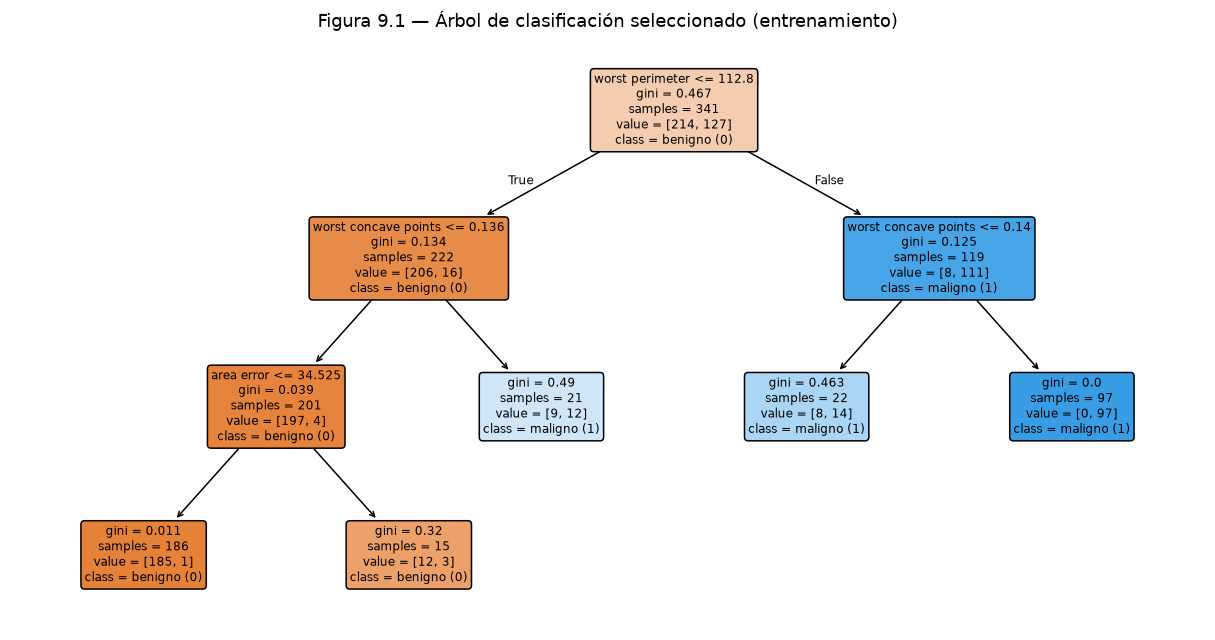

In [34]:
fig, ax = plt.subplots(figsize=(14, 7))
plot_tree(
    arbol_clf, max_depth=3, feature_names=list(Xc_train.columns),
    class_names=["benigno (0)", "maligno (1)"], filled=True, rounded=True,
    impurity=True, proportion=False, fontsize=8, ax=ax,
)
truncado = arbol_clf.get_depth() > 3
ax.set_title(
    "Figura 9.1 — Árbol de clasificación seleccionado (entrenamiento)"
    + (f"\nVisualización truncada a 3 niveles; profundidad real = {arbol_clf.get_depth()}" if truncado else "")
)
guardar_fig(fig, "ex9_arbol")
plt.show()

In [35]:
def regla_hasta_hoja(arbol, hoja, nombres):
    """Reconstruye la ruta raíz → hoja como lista de condiciones."""
    t = arbol.tree_
    padre = {}
    for nodo in range(t.node_count):
        for hijo, lado in [(t.children_left[nodo], "<="), (t.children_right[nodo], ">")]:
            if hijo != -1:
                padre[hijo] = (nodo, lado)
    condiciones, nodo = [], hoja
    while nodo in padre:
        p, lado = padre[nodo]
        condiciones.append(f"{nombres[t.feature[p]]} {lado} {t.threshold[p]:.4f}")
        nodo = p
    return condiciones[::-1]


t_ = arbol_clf.tree_
hojas = np.where(t_.children_left == -1)[0]
# Proporción de malignos por hoja contada directamente en entrenamiento
# (independiente de cómo guarde `tree_.value` cada versión de scikit-learn).
hoja_train = arbol_clf.apply(Xc_train)
info_hojas = pd.DataFrame({
    "Muestras": [int((hoja_train == h).sum()) for h in hojas],
    "Proporción de malignos": [yc_train[hoja_train == h].mean() for h in hojas],
}, index=hojas)
info_hojas.index.name = "Hoja"
print("Tabla 9.4 — Hojas del árbol seleccionado (entrenamiento)")
display(info_hojas.sort_values("Muestras", ascending=False))

# Se ilustra la hoja con más muestras de entrenamiento clasificadas como malignas.
hoja_ej = info_hojas[info_hojas["Proporción de malignos"] >= 0.5]["Muestras"].idxmax()
condiciones = regla_hasta_hoja(arbol_clf, hoja_ej, list(Xc_train.columns))
regla = "\n".join(f"{'    ' * i}if {c}:" for i, c in enumerate(condiciones))
regla += f"\n{'    ' * len(condiciones)}predecir maligno  # p = {info_hojas.loc[hoja_ej, 'Proporción de malignos']:.4f}"
print(f"Ruta hasta la hoja {hoja_ej} "
      f"({info_hojas.loc[hoja_ej, 'Muestras']} muestras de entrenamiento, "
      f"proporción de malignos = {info_hojas.loc[hoja_ej, 'Proporción de malignos']:.4f}):\n")
print(regla)

registrar("HojaEjMuestras", int(info_hojas.loc[hoja_ej, "Muestras"]))
_ = registrar("HojaEjProp", info_hojas.loc[hoja_ej, "Proporción de malignos"])

Tabla 9.4 — Hojas del árbol seleccionado (entrenamiento)


,Muestras,Proporción de malignos
Hoja,,
3,186,0.0054
8,97,1.0000
7,22,0.6364
5,21,0.5714
4,15,0.2000


Ruta hasta la hoja 8 (97 muestras de entrenamiento, proporción de malignos = 1.0000):

if worst perimeter > 112.8000:
    if worst concave points > 0.1396:
        predecir maligno  # p = 1.0000


TODO: análisis 9d

### e. Importancias, coeficientes y sobreajuste

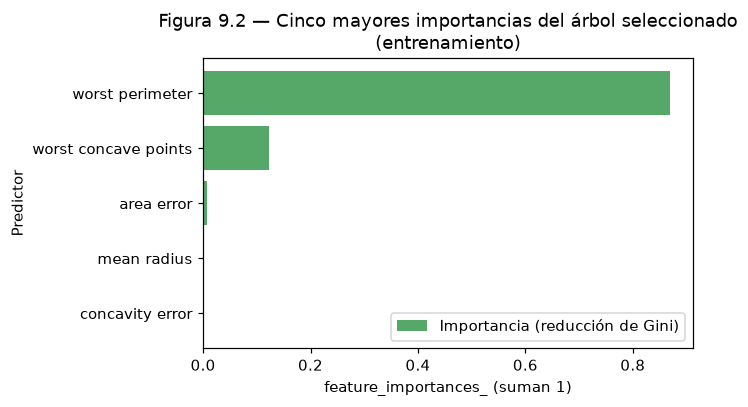

Predictores con importancia > 0: 3 de 30
Tabla 9.5 — Importancias del árbol frente a coeficientes de la logística


,Importancia árbol,Coef. logística,Rango |coef.| logística
worst perimeter,0.8686,0.6617,11
worst concave points,0.1234,0.5368,15
area error,0.0080,0.7822,7
mean radius,0.0000,0.4942,18
concavity error,0.0000,-0.0964,28


In [36]:
importancias = pd.Series(arbol_clf.feature_importances_, index=Xc_train.columns).sort_values(ascending=False)
top5 = importancias.head(5)

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.barh(top5.index[::-1], top5.values[::-1], color=COLORES["verde"], label="Importancia (reducción de Gini)")
ax.set_title("Figura 9.2 — Cinco mayores importancias del árbol seleccionado\n(entrenamiento)")
ax.set_xlabel("feature_importances_ (suman 1)")
ax.set_ylabel("Predictor")
ax.legend(loc="lower right")
plt.tight_layout()
guardar_fig(fig, "ex9_importancias")
plt.show()

comparacion_imp = pd.DataFrame({
    "Importancia árbol": top5,
    "Coef. logística": coefs_logit.loc[top5.index, "Coeficiente"],
    "Rango |coef.| logística": coefs_logit["|Coeficiente|"].rank(ascending=False).loc[top5.index].astype(int),
})
print(f"Predictores con importancia > 0: {(importancias > 0).sum()} de {len(importancias)}")
print("Tabla 9.5 — Importancias del árbol frente a coeficientes de la logística")
comparacion_imp

In [37]:
sobreajuste = tabla_9a.assign(
    **{"Brecha AUC (ent − val)": tabla_9a["ROC-AUC ent."] - tabla_9a["ROC-AUC val."],
       "Brecha F1 (ent − val)": tabla_9a["F1 ent. (t=0.5)"] - tabla_9a["F1 val. (t=0.5)"]}
)[["max_depth", "min_samples_leaf", "Profundidad real", "Hojas",
   "ROC-AUC ent.", "ROC-AUC val.", "Brecha AUC (ent − val)", "Brecha F1 (ent − val)"]]
print("Tabla 9.6 — Brechas entre entrenamiento y validación en la cuadrícula de árboles")
sobreajuste

Tabla 9.6 — Brechas entre entrenamiento y validación en la cuadrícula de árboles


,max_depth,min_samples_leaf,Profundidad real,Hojas,ROC-AUC ent.,ROC-AUC val.,Brecha AUC (ent − val),Brecha F1 (ent − val)
0,2,1,2,4,0.9726,0.9492,0.0234,0.0736
1,2,5,2,4,0.9726,0.9492,0.0234,0.0736
2,2,15,2,4,0.9754,0.9656,0.0098,0.0396
3,3,1,3,8,0.9893,0.8898,0.0995,0.0821
4,3,5,3,7,0.9928,0.9589,0.0339,0.0659
5,3,15,3,5,0.9854,0.9745,0.0110,0.0396
6,5,1,5,16,0.9999,0.9270,0.0729,0.0870
7,5,5,4,10,0.9976,0.9466,0.0510,0.0783
8,5,15,4,6,0.9886,0.9735,0.0151,0.0396
9,None,1,6,17,1.0000,0.9042,0.0958,0.1236


TODO: análisis 9e

## Ejercicio 10 — Evaluación final y recomendación sustentada

### Candidatos congelados antes de abrir prueba

Hasta este punto ninguna celda ha tocado `Xr_test`, `yr_test`, `Xc_test` ni
`yc_test`. Se registran primero los candidatos con sus predictores,
hiperparámetros y umbrales, y solo después se calcula cualquier métrica de
prueba; los modelos se usan tal como quedaron ajustados con entrenamiento.

In [38]:
candidatos = pd.DataFrame([
    {"Caso": "A (regresión)", "Candidato final": candidato_reg["Modelo"],
     "Predictores": f"{len(cols_reg_final)} ({', '.join(cols_reg_final) if len(cols_reg_final) < 4 else 'todos'})",
     "Hiperparámetros": "StandardScaler + LinearRegression" if modelo_reg_final is pipe_multi
        else ("LinearRegression" if modelo_reg_final is lr_simple
              else f"max_depth={arbol_reg.max_depth}, min_samples_leaf={arbol_reg.min_samples_leaf}"),
     "Umbral": "—", "Criterio de validación": f"RMSE = {candidato_reg['RMSE val.']:.4f}"},
    {"Caso": "B (clasificación)", "Candidato final": candidato_clf["Modelo"],
     "Predictores": f"{Xc_train.shape[1]} (todos)",
     "Hiperparámetros": (f"StandardScaler + LogisticRegression(C={C_sel:g}, lbfgs, L2)"
                         if candidato_clf["Orden"] == 0 else
                         f"max_depth={sel_arbol_clf['max_depth']}, min_samples_leaf={sel_arbol_clf['min_samples_leaf']}"),
     "Umbral": f"{candidato_clf['Umbral']:.1f}", "Criterio de validación": f"L = {int(candidato_clf['Costo L'])}"},
]).set_index("Caso")
print("Tabla 10.1 — Candidatos finales congelados (decididos con validación)")
candidatos

Tabla 10.1 — Candidatos finales congelados (decididos con validación)


,Candidato final,Predictores,Hiperparámetros,Umbral,Criterio de validación
Caso,,,,,
A (regresión),Regresión múltiple (10 predictores),10 (todos),StandardScaler + LinearRegression,—,RMSE = 51.1937
B (clasificación),Regresión logística (C = 1),30 (todos),"StandardScaler + LogisticRegression(C=1, lbfgs...",0.7,L = 5


### a. Regresión en prueba

In [39]:
modelos_reg_prueba = [
    ("Constante (media)", dummy_reg, list(Xr_train.columns)),
    ("Regresión simple (bmi)", lr_simple, ["bmi"]),
    ("Regresión múltiple (10 predictores)", pipe_multi, list(Xr_train.columns)),
    (tabla_7d.loc[2, "Modelo"], arbol_reg, list(Xr_train.columns)),
]
tabla_10a = pd.DataFrame(
    [{"Modelo": n, **metricas_reg(yr_test, m.predict(Xr_test[c]))} for n, m, c in modelos_reg_prueba]
).set_index("Modelo")
tabla_10a["RMSE validación"] = [rmse(yr_val, m.predict(Xr_val[c])) for _, m, c in modelos_reg_prueba]
tabla_10a["Candidato elegido"] = ["✓" if n == candidato_reg["Modelo"] else "" for n in tabla_10a.index]
print("Tabla 10.2 — Modelos de regresión en prueba (RMSE de validación como referencia)")
tabla_10a

Tabla 10.2 — Modelos de regresión en prueba (RMSE de validación como referencia)


,MAE,RMSE,R2,RMSE validación,Candidato elegido
Modelo,,,,,
Constante (media),63.5314,72.9002,-0.0031,75.6392,
Regresión simple (bmi),51.9829,63.8336,0.2309,58.5671,
Regresión múltiple (10 predictores),42.9245,54.1564,0.4464,51.1937,✓
"Árbol (max_depth=4, min_samples_leaf=30)",44.8448,58.2134,0.3604,56.7789,


In [40]:
claves_reg = {"Constante (media)": "Dummy", "Regresión simple (bmi)": "Simple",
              "Regresión múltiple (10 predictores)": "Multi", tabla_7d.loc[2, "Modelo"]: "ArbolReg"}
for nombre, clave in claves_reg.items():
    for met in ["MAE", "RMSE", "R2"]:
        registrar(f"Test{clave}{met.replace('2', 'dos')}", tabla_10a.loc[nombre, met])
rmse_val_cand, rmse_test_cand = candidato_reg["RMSE val."], tabla_10a.loc[candidato_reg["Modelo"], "RMSE"]
print(f"Candidato elegido: RMSE validación = {rmse_val_cand:.4f} · RMSE prueba = {rmse_test_cand:.4f} "
      f"(diferencia = {rmse_test_cand - rmse_val_cand:+.4f})")
_ = registrar("CandidatoRegRMSETest", rmse_test_cand)

Candidato elegido: RMSE validación = 51.1937 · RMSE prueba = 54.1564 (diferencia = +2.9627)


TODO: análisis 10a

### b. Clasificación en prueba

In [41]:
modelos_clf_prueba = [
    ("Referencia (prior)", dummy_clf, 0.5, "Dummy"),
    (f"Regresión logística (C = {C_sel:g})", logit_sel, t_logit, "Logit"),
    (comparacion_clf.loc[1, "Modelo"], arbol_clf, t_arbol, "ArbolClf"),
]
tabla_10b = pd.DataFrame(
    [{"Modelo": n, **metricas_clf(yc_test, m.predict_proba(Xc_test)[:, 1], t)} for n, m, t, _ in modelos_clf_prueba]
).set_index("Modelo")
print("Tabla 10.3 — Clasificación en prueba: métricas con los umbrales congelados")
display(tabla_10b[["Umbral", "Precisión", "Recall", "F1", "ROC-AUC"]])
print("Tabla 10.4 — Clasificación en prueba: errores y costo L = FP + 5FN")
display(tabla_10b[["Umbral", "TN", "FP", "FN", "TP", "Costo L"]])

for nombre, _, _, clave in modelos_clf_prueba:
    fila = tabla_10b.loc[nombre]
    for met, etiqueta in [("Precisión", "Prec"), ("Recall", "Recall"), ("F1", "FUno"), ("ROC-AUC", "AUC")]:
        registrar(f"Test{clave}{etiqueta}", fila[met])
    for met in ["FP", "FN", "TP", "TN"]:
        registrar(f"Test{clave}{met}", int(fila[met]))
    registrar(f"Test{clave}Costo", int(fila["Costo L"]))

Tabla 10.3 — Clasificación en prueba: métricas con los umbrales congelados


,Umbral,Precisión,Recall,F1,ROC-AUC
Modelo,,,,,
Referencia (prior),0.5000,0.0000,0.0000,0.0000,0.5000
Regresión logística (C = 1),0.7000,1.0000,0.9286,0.9630,0.9954
"Árbol (max_depth=3, min_samples_leaf=15)",0.2000,0.8542,0.9762,0.9111,0.9730


Tabla 10.4 — Clasificación en prueba: errores y costo L = FP + 5FN


,Umbral,TN,FP,FN,TP,Costo L
Modelo,,,,,,
Referencia (prior),0.5000,72,0,42,0,210
Regresión logística (C = 1),0.7000,72,0,3,39,15
"Árbol (max_depth=3, min_samples_leaf=15)",0.2000,65,7,1,41,12


TODO: análisis 10b

### c. Matrices de confusión y costo

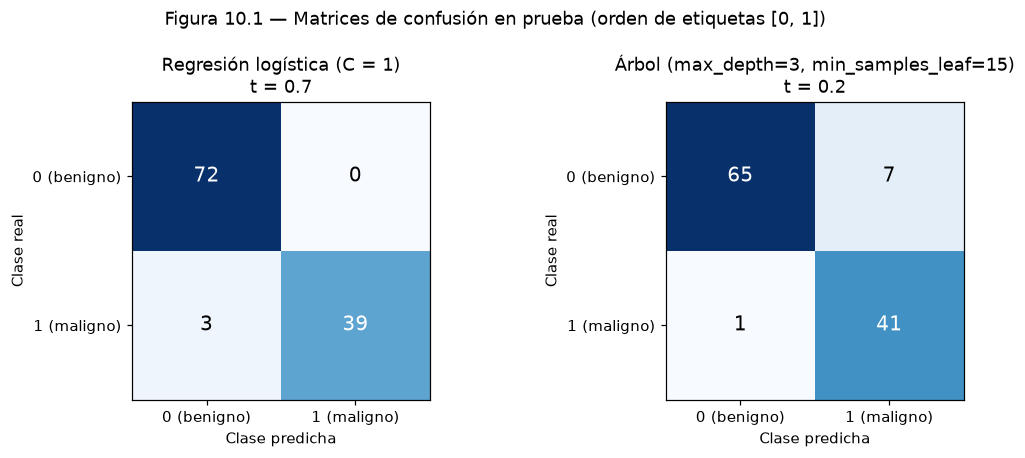

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, (nombre, modelo, t, _) in zip(axes, modelos_clf_prueba[1:]):
    cm = confusion_matrix(yc_test, predecir_umbral(modelo.predict_proba(Xc_test)[:, 1], t), labels=[0, 1])
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=13,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks([0, 1], ["0 (benigno)", "1 (maligno)"])
    ax.set_yticks([0, 1], ["0 (benigno)", "1 (maligno)"])
    ax.set_xlabel("Clase predicha")
    ax.set_ylabel("Clase real")
    ax.set_title(f"{nombre}\nt = {t}")
fig.suptitle("Figura 10.1 — Matrices de confusión en prueba (orden de etiquetas [0, 1])")
plt.tight_layout()
guardar_fig(fig, "ex10_matrices_confusion")
plt.show()

In [43]:
fila_cand = tabla_10b.loc[candidato_clf["Modelo"]]
fp, fn = int(fila_cand["FP"]), int(fila_cand["FN"])
print(f"Candidato elegido: {candidato_clf['Modelo']} (t = {candidato_clf['Umbral']})")
print(f"Verificación del costo: L = FP + 5·FN = {fp} + 5·{fn} = {fp + 5 * fn}")
assert fp + 5 * fn == int(fila_cand["Costo L"])

Candidato elegido: Regresión logística (C = 1) (t = 0.7)
Verificación del costo: L = FP + 5·FN = 0 + 5·3 = 15


TODO: análisis 10c

### d. Recomendación

El texto se guarda en una variable para contar sus palabras en la misma
celda y comprobar que está entre 250 y 350.

In [44]:
from IPython.display import Markdown

RECOMENDACION = """TODO"""

n_palabras = len(re.findall(r"\b[\w’'.,-]+\b", RECOMENDACION))
display(Markdown(RECOMENDACION))
print(f"Número de palabras: {n_palabras}")

TODO

Número de palabras: 1


### Cifras para el documento LaTeX

In [45]:
escribir_macros()

114 macros escritas en ../latex/generado/resultados.tex
